# Business Problem Understanding or  Project Understanding

- predict whether the customer is eligible for the loan or not

In [1]:
import numpy as np
import pandas as pd

import warnings
warnings.simplefilter("ignore")

# Extract

- Extract the raw data
- Data Understanding
    - Understanding meaning of each column name very clearly
- Data Exploration
    - Observe the internal data
    - Ovserve the values in each column
    - Checking unique values of each column
- Exploratory Data Analysis (EDA) : observing the entire raw data
    - observing the raw data
    - other than unique...  what are remaining check on raw data

**extract raw data**

In [2]:
df = pd.read_csv("LoanData.csv")
df.head()

,Loan_ID,Gender,Married,Dependents,Education,Self_Employed,ApplicantIncome,CoapplicantIncome,LoanAmount,Loan_Amount_Term,Credit_History,Property_Area,Loan_Status
0,LP001002,Male,No,0,Graduate,No,5849,0.0,NaN,360.0,1.0,Urban,Y
1,LP001003,Male,Yes,1,Graduate,No,4583,1508.0,128.0,360.0,1.0,Rural,N
2,LP001005,Male,Yes,0,Graduate,Yes,3000,0.0,66.0,360.0,1.0,Urban,Y
3,LP001006,Male,Yes,0,Not Graduate,No,2583,2358.0,120.0,360.0,1.0,Urban,Y
4,LP001008,Male,No,0,Graduate,No,6000,0.0,141.0,360.0,1.0,Urban,Y


**Data Understanding**
- Unserstand meaning of each & every column name very clearly

**Data Exploration**
- Exploring the given raw data

In [3]:
df.shape

(614, 13)

- in the given dataset, it has 614 records with 13 columns

In [4]:
df.columns.tolist()

['Loan_ID',
 'Gender',
 'Married',
 'Dependents',
 'Education',
 'Self_Employed',
 'ApplicantIncome',
 'CoapplicantIncome',
 'LoanAmount',
 'Loan_Amount_Term',
 'Credit_History',
 'Property_Area',
 'Loan_Status']

- all column names are as per syntax, no need to rename

In [5]:
df['Loan_ID'].unique()

array(['LP001002', 'LP001003', 'LP001005', 'LP001006', 'LP001008',
       'LP001011', 'LP001013', 'LP001014', 'LP001018', 'LP001020',
       'LP001024', 'LP001027', 'LP001028', 'LP001029', 'LP001030',
       'LP001032', 'LP001034', 'LP001036', 'LP001038', 'LP001041',
       'LP001043', 'LP001046', 'LP001047', 'LP001050', 'LP001052',
       'LP001066', 'LP001068', 'LP001073', 'LP001086', 'LP001087',
       'LP001091', 'LP001095', 'LP001097', 'LP001098', 'LP001100',
       'LP001106', 'LP001109', 'LP001112', 'LP001114', 'LP001116',
       'LP001119', 'LP001120', 'LP001123', 'LP001131', 'LP001136',
       'LP001137', 'LP001138', 'LP001144', 'LP001146', 'LP001151',
       'LP001155', 'LP001157', 'LP001164', 'LP001179', 'LP001186',
       'LP001194', 'LP001195', 'LP001197', 'LP001198', 'LP001199',
       'LP001205', 'LP001206', 'LP001207', 'LP001213', 'LP001222',
       'LP001225', 'LP001228', 'LP001233', 'LP001238', 'LP001241',
       'LP001243', 'LP001245', 'LP001248', 'LP001250', 'LP0012

In [6]:
df['Loan_ID'].nunique()

614

- loan_id has all unique values

In [7]:
df["Gender"].unique()

array(['Male', 'Female', nan], dtype=object)

- gender column consists some missing values

In [8]:
df["Married"].unique()

array(['No', 'Yes', nan], dtype=object)

- Married column consists of yes/no along with some missing values

In [9]:
df["Dependents"].unique()

array(['0', '1', '2', '3+', nan], dtype=object)

- wrong data (3+)
- datatype is wrong as no.of dependents should be int

In [10]:
df["Education"].unique()

array(['Graduate', 'Not Graduate'], dtype=object)

In [11]:
df["Self_Employed"].unique()

array(['No', 'Yes', nan], dtype=object)

In [12]:
df["ApplicantIncome"].unique()

array([ 5849,  4583,  3000,  2583,  6000,  5417,  2333,  3036,  4006,
       12841,  3200,  2500,  3073,  1853,  1299,  4950,  3596,  3510,
        4887,  2600,  7660,  5955,  3365,  3717,  9560,  2799,  4226,
        1442,  3750,  4166,  3167,  4692,  3500, 12500,  2275,  1828,
        3667,  3748,  3600,  1800,  2400,  3941,  4695,  3410,  5649,
        5821,  2645,  4000,  1928,  3086,  4230,  4616, 11500,  2708,
        2132,  3366,  8080,  3357,  3029,  2609,  4945,  5726, 10750,
        7100,  4300,  3208,  1875,  4755,  5266,  1000,  3333,  3846,
        2395,  1378,  3988,  2366,  8566,  5695,  2958,  6250,  3273,
        4133,  3620,  6782,  2484,  1977,  4188,  1759,  4288,  4843,
       13650,  4652,  3816,  3052, 11417,  7333,  3800,  2071,  5316,
        2929,  3572,  7451,  5050, 14583,  2214,  5568, 10408,  5667,
        2137,  2957,  3692, 23803,  3865, 10513,  6080, 20166,  2014,
        2718,  3459,  4895,  3316, 14999,  4200,  5042,  6950,  2698,
       11757,  2330,

In [13]:
df['CoapplicantIncome'].astype(float)

0         0.0
1      1508.0
2         0.0
3      2358.0
4         0.0
        ...  
609       0.0
610       0.0
611     240.0
612       0.0
613       0.0
Name: CoapplicantIncome, Length: 614, dtype: float64

In [14]:
df["income"] = df["ApplicantIncome"]+df["CoapplicantIncome"]

df.drop(columns=["ApplicantIncome","CoapplicantIncome"],inplace = True)

In [15]:
df['LoanAmount'] = df['LoanAmount']*1000

In [16]:
df['LoanAmount'].unique()

array([    nan, 128000.,  66000., 120000., 141000., 267000.,  95000.,
       158000., 168000., 349000.,  70000., 109000., 200000., 114000.,
        17000., 125000., 100000.,  76000., 133000., 115000., 104000.,
       315000., 116000., 112000., 151000., 191000., 122000., 110000.,
        35000., 201000.,  74000., 106000., 320000., 144000., 184000.,
        80000.,  47000.,  75000., 134000.,  96000.,  88000.,  44000.,
       286000.,  97000., 135000., 180000.,  99000., 165000., 258000.,
       126000., 312000., 136000., 172000.,  81000., 187000., 113000.,
       176000., 130000., 111000., 167000., 265000.,  50000., 210000.,
       175000., 131000., 188000.,  25000., 137000., 160000., 225000.,
       216000.,  94000., 139000., 152000., 118000., 185000., 154000.,
        85000., 259000., 194000.,  93000., 370000., 182000., 650000.,
       102000., 290000.,  84000., 242000., 129000.,  30000., 244000.,
       600000., 255000.,  98000., 275000., 121000.,  63000., 700000.,
        87000., 1010

In [17]:
df["Loan_Amount_Term"].unique()

array([360., 120., 240.,  nan, 180.,  60., 300., 480.,  36.,  84.,  12.])

In [18]:
df["Credit_History"].unique()

array([ 1.,  0., nan])

In [19]:
df['Credit_History'] = df['Credit_History'].replace({0:"no",1:"yes"})

In [20]:
df['Credit_History'].unique()

array(['yes', 'no', nan], dtype=object)

In [21]:
df["Property_Area"].unique()

array(['Urban', 'Rural', 'Semiurban'], dtype=object)

In [22]:
df["Loan_Status"].unique()

array(['Y', 'N'], dtype=object)

In [23]:
continous = ['income', 'LoanAmount']

d_categorical = ['Gender','Married','Education','Self_Employed','Property_Area', 'Loan_Status','Credit_History']

d_count = ["Loan_Amount_Term",'Dependents']

**Exploratory Data Analysis**

In [24]:
df[continous].describe()

,income,LoanAmount
count,614.000000,592.000000
mean,7024.705081,146412.162162
std,6458.663872,85587.325236
min,1442.000000,9000.000000
25%,4166.000000,100000.000000
50%,5416.500000,128000.000000
75%,7521.750000,168000.000000
max,81000.000000,700000.000000


In [25]:
df[d_categorical].describe()

,Gender,Married,Education,Self_Employed,Property_Area,Loan_Status,Credit_History
count,601,611,614,582,614,614,564
unique,2,2,2,2,3,2,2
top,Male,Yes,Graduate,No,Semiurban,Y,yes
freq,489,398,480,500,233,422,475


In [26]:
df.isnull().sum()

Loan_ID              0
Gender              13
Married              3
Dependents          15
Education            0
Self_Employed       32
LoanAmount          22
Loan_Amount_Term    14
Credit_History      50
Property_Area        0
Loan_Status          0
income               0
dtype: int64

# Transform (Data Preparation)

1. data cleaning
 - wrong data
 - missing value      
 - wrong data type
 - duplicates
 - outliers
 - unimportant columns
 

2. Data Transformation or Data Wrangling
 - encoding
 - scaling

In [27]:
df[df["Dependents"]=="3+"]

,Loan_ID,Gender,Married,Dependents,Education,Self_Employed,LoanAmount,Loan_Amount_Term,Credit_History,Property_Area,Loan_Status,income
7,LP001014,Male,Yes,3+,Graduate,No,158000.0,360.0,no,Semiurban,N,5540.0
34,LP001100,Male,No,3+,Graduate,No,320000.0,360.0,yes,Rural,N,15500.0
61,LP001206,Male,Yes,3+,Graduate,No,99000.0,360.0,yes,Urban,Y,3029.0
68,LP001238,Male,Yes,3+,Not Graduate,Yes,125000.0,60.0,yes,Urban,Y,7100.0
73,LP001250,Male,Yes,3+,Not Graduate,No,95000.0,NaN,no,Semiurban,N,4755.0
74,LP001253,Male,Yes,3+,Graduate,Yes,187000.0,360.0,yes,Semiurban,Y,7040.0
78,LP001263,Male,Yes,3+,Graduate,No,180000.0,300.0,no,Semiurban,N,7167.0
79,LP001264,Male,Yes,3+,Not Graduate,Yes,130000.0,360.0,NaN,Semiurban,Y,5499.0
109,LP001384,Male,Yes,3+,Not Graduate,No,94000.0,480.0,yes,Semiurban,Y,2825.0
126,LP001448,NaN,Yes,3+,Graduate,No,370000.0,360.0,yes,Rural,Y,23803.0


**treat wrong data**

In [28]:
df["Dependents"].replace("3+",3,inplace=True)

**treat missing values**

In [29]:
df["Gender"].fillna(df["Gender"].mode()[0],inplace =True)

df["Dependents"].fillna(df["Dependents"].mode()[0],inplace=True)

df["Self_Employed"].fillna(df["Self_Employed"].mode()[0],inplace=True)

df["Married"].fillna(df["Married"].mode()[0],inplace=True)

df.dropna(inplace=True)

In [30]:
df.isnull().sum()

Loan_ID             0
Gender              0
Married             0
Dependents          0
Education           0
Self_Employed       0
LoanAmount          0
Loan_Amount_Term    0
Credit_History      0
Property_Area       0
Loan_Status         0
income              0
dtype: int64

**treat wrong datatype**

In [31]:
df["Dependents"] = df["Dependents"].astype("int")

df["Loan_Amount_Term"] = df["Loan_Amount_Term"].astype("int")

**Drop unimportant column**

In [32]:
df.drop(columns=["Loan_ID"],inplace=True)

**Encoding**

In [33]:
binary_categorical = ["Gender","Married","Education","Self_Employed","Credit_History","Loan_Status"]

df[binary_categorical] = pd.get_dummies(df[binary_categorical],drop_first=True,dtype=int)

In [34]:
from sklearn.preprocessing import LabelEncoder
le = LabelEncoder()
df["Property_Area"]=le.fit_transform(df["Property_Area"])

In [35]:
df

,Gender,Married,Dependents,Education,Self_Employed,LoanAmount,Loan_Amount_Term,Credit_History,Property_Area,Loan_Status,income
1,1,1,1,0,0,128000.0,360,1,0,0,6091.0
2,1,1,0,0,1,66000.0,360,1,2,1,3000.0
3,1,1,0,1,0,120000.0,360,1,2,1,4941.0
4,1,0,0,0,0,141000.0,360,1,2,1,6000.0
5,1,1,2,0,1,267000.0,360,1,2,1,9613.0
...,...,...,...,...,...,...,...,...,...,...,...
609,0,0,0,0,0,71000.0,360,1,0,1,2900.0
610,1,1,3,0,0,40000.0,180,1,0,1,4106.0
611,1,1,1,0,0,253000.0,360,1,2,1,8312.0
612,1,1,2,0,0,187000.0,360,1,2,1,7583.0


In [36]:
df.to_excel("cleaned.xlsx", index=False)

# Load 

- Load the clean data

In [37]:
df = pd.read_excel("cleaned.xlsx")
df

,Gender,Married,Dependents,Education,Self_Employed,LoanAmount,Loan_Amount_Term,Credit_History,Property_Area,Loan_Status,income
0,1,1,1,0,0,128000,360,1,0,0,6091.0
1,1,1,0,0,1,66000,360,1,2,1,3000.0
2,1,1,0,1,0,120000,360,1,2,1,4941.0
3,1,0,0,0,0,141000,360,1,2,1,6000.0
4,1,1,2,0,1,267000,360,1,2,1,9613.0
...,...,...,...,...,...,...,...,...,...,...,...
524,0,0,0,0,0,71000,360,1,0,1,2900.0
525,1,1,3,0,0,40000,180,1,0,1,4106.0
526,1,1,1,0,0,253000,360,1,2,1,8312.0
527,1,1,2,0,0,187000,360,1,2,1,7583.0


In [38]:
x = df.drop("Loan_Status",axis=1)
y = df["Loan_Status"]

In [39]:
train = []
test = []
cv = []

for i in range(0,101):
    from sklearn.model_selection import train_test_split
    x_train,x_test,y_train,y_test = train_test_split(x,y, test_size=0.2,random_state = i)
    
    from sklearn.linear_model import LogisticRegression
    log = LogisticRegression()
    log.fit(x_train,y_train)
    
    y_pred_train = log.predict(x_train)
    y_pred_test = log.predict(x_test)
    
    from sklearn.metrics import accuracy_score
    train.append(accuracy_score(y_train,y_pred_train))
    test.append(accuracy_score(y_test, y_pred_test))
    
    from sklearn.model_selection import cross_val_score
    cv.append(cross_val_score(log,x_train,y_train,cv=5,scoring="accuracy").mean())
    
em = pd.DataFrame({"train":train,"test":test,"cv":cv})
gm = em[(abs(em["train"]-em["test"])<=0.05)&(abs(em["test"]-em["cv"])<=0.05)]
print("best_random_number:",gm[gm["cv"]==gm["cv"].max()].index.to_list()[0])

best_random_number: 45


**train-test-split**

In [40]:
x_train,x_test,y_train,y_test = train_test_split(x,y,train_size=0.8,random_state=70)

**check whether train data is balanced or imbalanced**

In [41]:
y_train.value_counts()

Loan_Status
1    297
0    126
Name: count, dtype: int64

- since, the dataset imbalanced 
- we convert the imbalced dataset to balanced data
- for this dataset,we apply oversampling using SMOTE (as no.of records of minority class <500)

# Modelling & Evaluation

In [43]:
from sklearn.linear_model import LogisticRegression
l = LogisticRegression()
l.fit(x_train,y_train)

LogisticRegression()

In [44]:
from sklearn.linear_model import LogisticRegression
l = LogisticRegression()
l.fit(x_train,y_train)

y_train_pred = l.predict(x_train)
print("Train_accuracy: ",accuracy_score(y_train,y_train_pred))

print("cross_validation: ",cross_val_score(l,x_train,y_train,cv=5,scoring="accuracy").mean())

y_test_pred = l.predict(x_test)
print("test_accuracy: ",accuracy_score(y_test,y_test_pred))

Train_accuracy:  0.8203309692671394
cross_validation:  0.8110084033613445
test_accuracy:  0.7641509433962265


**K-NN (K-Nearest Neighbors)**

In [45]:
from sklearn.neighbors import KNeighborsClassifier
estimator = KNeighborsClassifier()

param_grid = {"n_neighbors":list(range(1,150))}

from sklearn.model_selection import GridSearchCV
cv_classifier = GridSearchCV(estimator,param_grid,cv=5,scoring="accuracy")

cv_classifier.fit(x_train,y_train)

cv_classifier.best_params_

{'n_neighbors': 41}

In [46]:
from sklearn.neighbors import KNeighborsClassifier
knn = KNeighborsClassifier(n_neighbors=41)
knn.fit(x_train,y_train)

y_pred_train = knn.predict(x_train)
print("train_accuracy: ",accuracy_score(y_train,y_pred_train))

print("cross_validation: ",cross_val_score(knn,x_train,y_train,cv=5,scoring="accuracy").mean())

y_pred_test = knn.predict(x_test)
print("test_accuracy: ",accuracy_score(y_test,y_pred_test))

train_accuracy:  0.7021276595744681
cross_validation:  0.7021288515406162
test_accuracy:  0.6509433962264151


**SVM (Support Vector Machines)**

In [ ]:
from sklearn.svm import SVC

estimator = SVC()
param_grid = {"C":[0.01,0.1,1,10],"kernel":["linear","poly","rbf","sigmoid"]}

svm_grid= GridSearchCV(estimator,param_grid,scoring = "accuracy",cv=5)
svm_grid.fit(x_train,y_train)

svm_grid.best_params_

In [ ]:
from sklearn.svm import SVC
s = SVC(C=0.1,kernel="linear")
s.fit(x_train,y_train)

y_pred_train = s.predict(x_train)
print("train_accuracy: ",accuracy_score(y_train,y_pred_train))

print("cross_validation: ",cross_val_score(s,x_train,y_train,cv=5,scoring="accuracy").mean())

y_pred_test = s.predict(x_test)
print("test_accuracy: ",accuracy_score(y_test,y_pred_test))

In [ ]:
from sklearn.naive_bayes import MultinomialNB                    # import ML Algorithm
model=MultinomialNB()                                            # save as model name
model.fit(X_train,y_train)                                       # fit on train data

ypred_train = model.predict(X_train)
from sklearn.metrics import accuracy_score
print("train Accuracy:",accuracy_score(y_train,ypred_train))

from sklearn.model_selection import cross_val_score
cross_val_score(model,X,y,cv=5).mean()

ypred_test = model.predict(X_test)
print("test accuraccuracy_score(y_test,ypred_test)

**Decision Tree**

In [50]:
from sklearn.tree import DecisionTreeClassifier
dt_base = DecisionTreeClassifier(random_state=70)
dt_base.fit(x_train,y_train)

y_pred_train = dt_base.predict(x_train)
y_pred_test = dt_base.predict(x_test)

print("train_accuracy:",accuracy_score(y_pred_train,y_train))
print("test_accuracy: ",accuracy_score(y_test,y_pred_test))
print("cross_validation:",cross_val_score(dt,x_train,y_train,cv=5,scoring="accuracy").mean())

train_accuracy: 1.0
test_accuracy:  0.6886792452830188
cross_validation: 0.8227731092436976


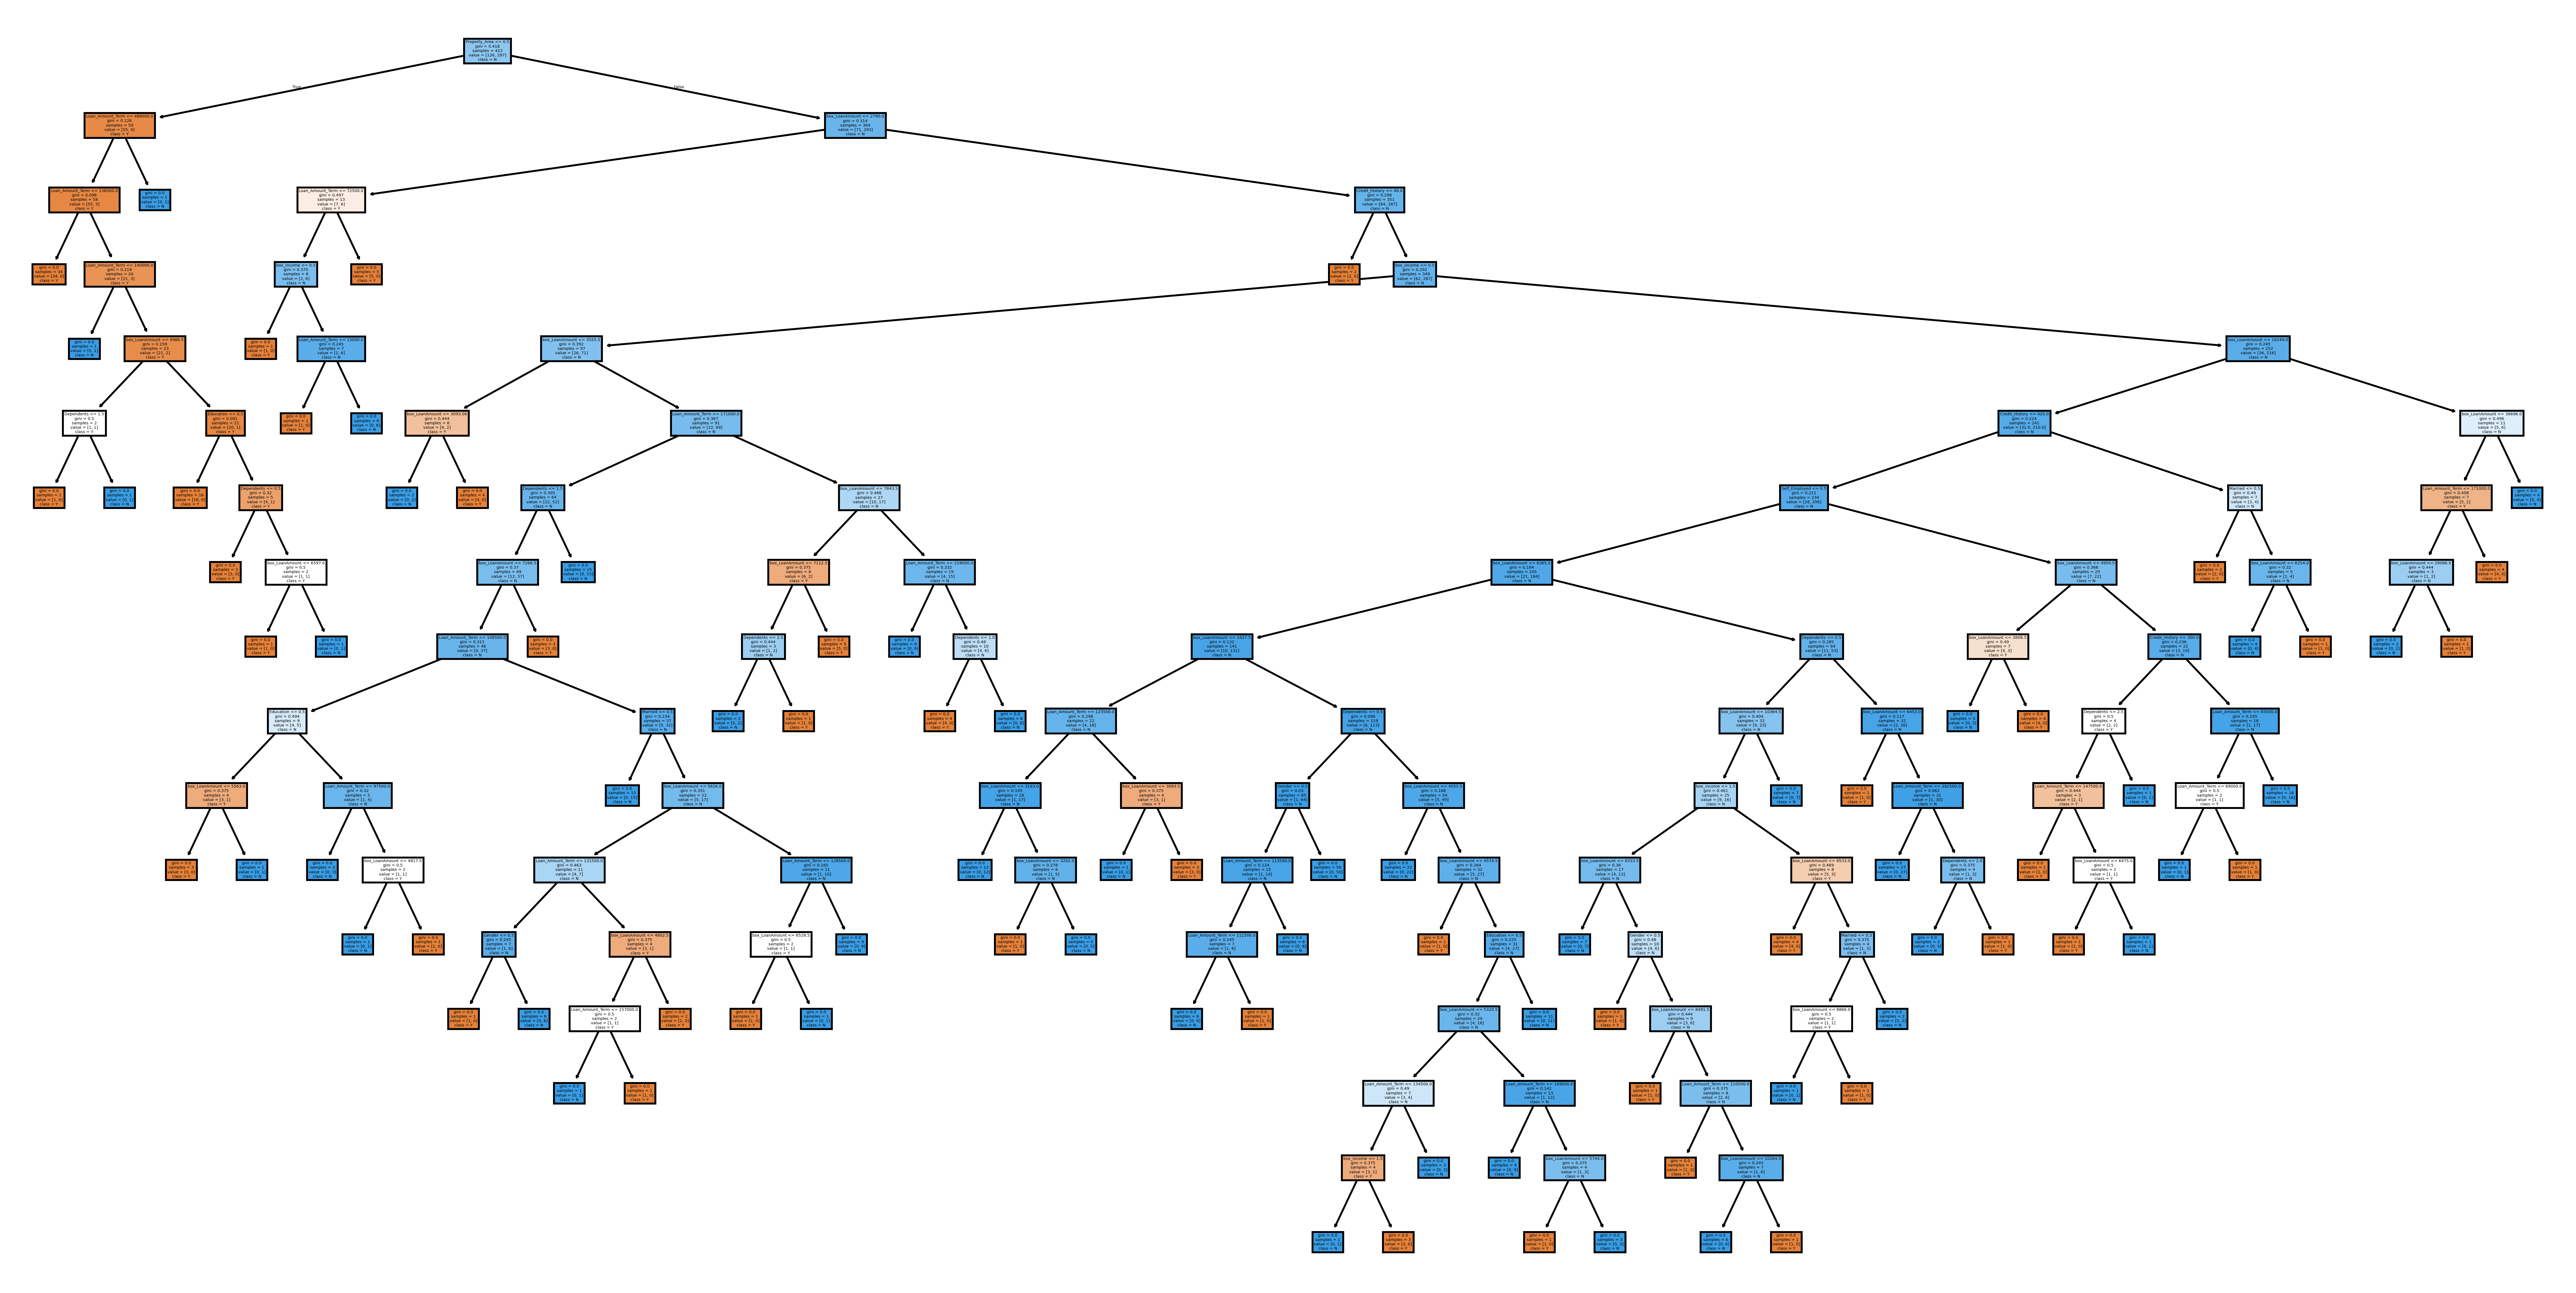

In [51]:
from sklearn.tree import plot_tree
import matplotlib.pyplot as plt
plt.figure(figsize=(24,12),dpi=500)

plot_tree(dt_base,filled=True,
          feature_names=['Gender', 'Married', 'Dependents', 'Education', 'Self_Employed',
       'Loan_Amount_Term', 'Credit_History', 'Property_Area', 'box_income',
       'box_LoanAmount'],class_names=["Y","N"])

plt.show()

In [48]:
x_train

,Gender,Married,Dependents,Education,Self_Employed,LoanAmount,Loan_Amount_Term,Credit_History,Property_Area,income
131,1,0,0,0,0,120000,360,1,0,5063.0
97,0,0,0,0,0,259000,360,1,2,10408.0
384,1,1,2,0,0,150000,360,0,0,5050.0
445,0,0,0,1,0,95000,360,1,0,3400.0
335,1,1,3,0,0,275000,360,1,0,9504.0
...,...,...,...,...,...,...,...,...,...,...
59,1,1,0,0,0,172000,360,1,2,6274.0
316,0,0,0,0,1,55000,360,1,1,15759.0
114,1,1,2,0,0,185000,360,1,0,7125.0
214,1,0,0,1,1,104000,360,1,0,4750.0


In [58]:
dt_base.feature_importances_

array([0.0147898 , 0.01836791, 0.07437967, 0.01252965, 0.00554378,
       0.17075238, 0.02983975, 0.31184322, 0.03748964, 0.32446421])

In [64]:
feats = pd.DataFrame(data=np.round(dt_base.feature_importances_*100,2),
                    index=x.columns,
                    columns=["Feature Importance"])
feats.sort_values(by="Feature Importance",ascending=False)

,Feature Importance
income,32.45
Credit_History,31.18
LoanAmount,17.08
Dependents,7.44
Property_Area,3.75
Loan_Amount_Term,2.98
Married,1.84
Gender,1.48
Education,1.25
Self_Employed,0.55


In [65]:
estimator = DecisionTreeClassifier(random_state=70)
param_grid = {"criterion":["gini","entropy"],
              "max_depth":list(range(1,17))}

from sklearn.model_selection import GridSearchCV
grid = GridSearchCV(estimator,param_grid,scoring="accuracy",cv=5)
grid.fit(x_train,y_train)

grid.best_params_

{'criterion': 'gini', 'max_depth': 1}

In [66]:
from sklearn.tree import DecisionTreeClassifier
dt_opt = DecisionTreeClassifier(random_state=70,max_depth=1)
dt_opt.fit(x_train,y_train)

y_pred_train = dt_opt.predict(x_train)
y_pred_test = dt_opt.predict(x_test)

print("train_accuracy:",accuracy_score(y_pred_train,y_train))
print("test_accuracy: ",accuracy_score(y_test,y_pred_test))
print("cross_validation:",cross_val_score(dt,x_train,y_train,cv=5,scoring="accuracy").mean())

train_accuracy: 0.8226950354609929
test_accuracy:  0.7830188679245284
cross_validation: 0.8227731092436976


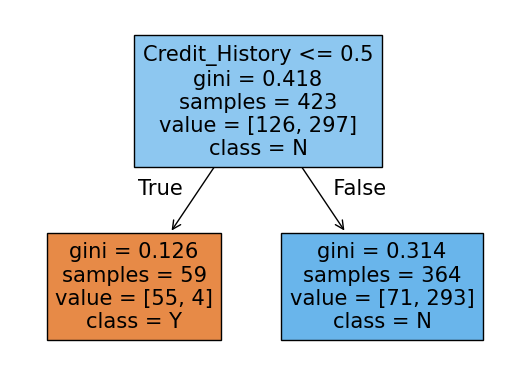

In [75]:
from sklearn.tree import plot_tree
import matplotlib.pyplot as plt


plot_tree(dt_opt,filled=True,
          feature_names= x_train.columns,
          class_names=["Y","N"])

plt.show()

In [67]:
feats = pd.DataFrame(data=np.round(dt_opt.feature_importances_*100,2),
                    index=x.columns,
                    columns=["Feature Importance"])
feats.sort_values(by="Feature Importance",ascending=False)

,Feature Importance
Credit_History,100.0
Gender,0.0
Married,0.0
Dependents,0.0
Self_Employed,0.0
Education,0.0
LoanAmount,0.0
Loan_Amount_Term,0.0
Property_Area,0.0
income,0.0


**Random Forest**

In [78]:
from sklearn.ensemble import RandomForestClassifier

estimator =RandomForestClassifier(random_state=70)

param_grid = {"n_estimators":list(range(20,30))}

grid = GridSearchCV(estimator,param_grid,scoring="accuracy",cv=5)

grid.fit(x_train,y_train)

grid.best_params_

{'n_estimators': 25}

In [79]:
grid.best_estimator_.feature_importances_

array([0.02327185, 0.02250402, 0.05479835, 0.0224415 , 0.01895125,
       0.21299624, 0.05025182, 0.27459751, 0.05311237, 0.26707508])

In [80]:
feats = pd.DataFrame(data=grid.best_estimator_.feature_importances_,
                    index=x_train.columns,
                    columns=["Feature Importacne"])
feats_im = feats[feats["Feature Importacne"]>0]
imp_features = feats_im.index.to_list()
imp_features

['Gender',
 'Married',
 'Dependents',
 'Education',
 'Self_Employed',
 'LoanAmount',
 'Loan_Amount_Term',
 'Credit_History',
 'Property_Area',
 'income']

In [81]:
x2= x[imp_features] 
x2_train,x2_test,y2_train,y2_test = train_test_split(x2,y,train_size=0.8,random_state=70)

rf = RandomForestClassifier(n_estimators=25,random_state=70)
rf.fit(x2_train,y2_train)

y2_pred_train = rf.predict(x2_train)
print("train_accuracy:",accuracy_score(y2_train,y2_pred_train))

print("cv:",cross_val_score(rf,x2_train,y2_train,cv=5,scoring="accuracy").mean())

y2_pred_test = rf.predict(x2_test)
print("test_accuracy:",accuracy_score(y2_test,y2_pred_test))

train_accuracy: 1.0
cv: 0.8133613445378151
test_accuracy: 0.7547169811320755


**AdaBoost**

In [82]:
from sklearn.ensemble import AdaBoostClassifier, GradientBoostingClassifier
ab= AdaBoostClassifier()
param_grid_ab = {"n_estimators":list(range(1,100))}

grid_ab = GridSearchCV(ab,param_grid_ab,cv=5,scoring="accuracy")
grid_ab.fit(x_train,y_train)

grid_ab.best_params_

{'n_estimators': 15}

In [83]:
grid_ab.best_estimator_.feature_importances_

array([0.        , 0.        , 0.        , 0.        , 0.        ,
       0.10125468, 0.04101935, 0.5122937 , 0.06393471, 0.28149757])

In [84]:
feats = pd.DataFrame(data=grid_ab.best_estimator_.feature_importances_,
                    index=x.columns,
                    columns=["Feature Importacne"])
feats
feats_im = feats[feats["Feature Importacne"]>0]
imp_features = feats_im.index.to_list()
imp_features

['LoanAmount', 'Loan_Amount_Term', 'Credit_History', 'Property_Area', 'income']

In [85]:
x3= x[imp_features] 
x3_train,x3_test,y3_train,y3_test = train_test_split(x3,y,train_size=0.8,random_state=70)

ab = AdaBoostClassifier(n_estimators=15,random_state=70)
ab.fit(x3_train,y3_train)

y3_pred_train = ab.predict(x3_train)
print("train_accuracy:",accuracy_score(y3_train,y3_pred_train))

print("cv:",cross_val_score(ab,x3_train,y3_train,cv=5,scoring="accuracy").mean())

y3_pred_test = ab.predict(x3_test)
print("test_accuracy:",accuracy_score(y3_test,y3_pred_test))

train_accuracy: 0.8226950354609929
cv: 0.82515406162465
test_accuracy: 0.7830188679245284


**Gradient Boost**

In [87]:
gb = GradientBoostingClassifier()
param_grid_gb = {"n_estimators":list(range(1,100))}

grid_gb = GridSearchCV(gb,param_grid_gb,cv=5,scoring="accuracy")
grid_gb.fit(x_train,y_train)
grid_gb.best_params_

{'n_estimators': 29}

In [88]:
grid_gb.best_estimator_.feature_importances_

array([0.        , 0.00538654, 0.00174288, 0.001623  , 0.00659255,
       0.11346882, 0.04704982, 0.63346454, 0.0413115 , 0.14936036])

In [89]:
feats_gb = pd.DataFrame(data=grid_gb.best_estimator_.feature_importances_,
                    index=x.columns,
                    columns=["Feature Importacne"])
feats_im = feats_gb[feats_gb["Feature Importacne"]>0]
imp_features = feats_im.index.to_list()
imp_features

['Married',
 'Dependents',
 'Education',
 'Self_Employed',
 'LoanAmount',
 'Loan_Amount_Term',
 'Credit_History',
 'Property_Area',
 'income']

In [90]:
x4= x[imp_features] 
x4_train,x4_test,y4_train,y4_test = train_test_split(x4,y,train_size=0.8,random_state=70)

gb = GradientBoostingClassifier(n_estimators=30,learning_rate=0.1)
gb.fit(x4_train,y4_train)

y4_pred_train = gb.predict(x4_train)
print("train_accuracy:",accuracy_score(y4_train,y4_pred_train))

print("cv:",cross_val_score(gb,x4_train,y4_train,cv=5,scoring="accuracy").mean())

y4_pred_test = gb.predict(x4_test)
print("test_accuracy:",accuracy_score(y4_test,y4_pred_test))

train_accuracy: 0.8628841607565012
cv: 0.8250980392156864
test_accuracy: 0.7452830188679245


**xgboost classifier**

In [93]:
!pip install xgboost  

   ---------------------------------------- 0.0/101.7 MB ? eta -:--:--
    --------------------------------------- 2.1/101.7 MB 10.9 MB/s eta 0:00:10
   - -------------------------------------- 4.7/101.7 MB 11.5 MB/s eta 0:00:09
   -- ------------------------------------- 7.3/101.7 MB 11.6 MB/s eta 0:00:09
   --- ------------------------------------ 10.0/101.7 MB 11.6 MB/s eta 0:00:08
   ---- ----------------------------------- 12.6/101.7 MB 11.7 MB/s eta 0:00:08
   ----- ---------------------------------- 14.9/101.7 MB 11.6 MB/s eta 0:00:08
   ------ --------------------------------- 17.6/101.7 MB 11.6 MB/s eta 0:00:08
   ------- -------------------------------- 19.9/101.7 MB 11.6 MB/s eta 0:00:08
   -------- ------------------------------- 22.5/101.7 MB 11.7 MB/s eta 0:00:07
   --------- ------------------------------ 25.2/101.7 MB 11.7 MB/s eta 0:00:07
   ---------- ----------------------------- 27.8/101.7 MB 11.7 MB/s eta 0:00:07
   ----------- ---------------------------- 30.1/101

In [94]:
from xgboost import XGBClassifier

estimator_xgb = XGBClassifier()

param_grid = {"n_estimators":list(range(1,20))}

grid_xgb = GridSearchCV(estimator_xgb,param_grid,cv=5,scoring="accuracy")
grid_xgb.fit(x_train,y_train)

grid_xgb.best_params_

{'n_estimators': 10}

In [95]:
f_xgb = pd.DataFrame(data=grid_xgb.best_estimator_.feature_importances_,
                    index=x.columns,
                    columns=["Importance"])
imp_features_list_xgb = f_xgb[f_xgb["Importance"]>0].index.to_list()
imp_features_list_xgb

['Gender',
 'Married',
 'Dependents',
 'Education',
 'Self_Employed',
 'LoanAmount',
 'Loan_Amount_Term',
 'Credit_History',
 'Property_Area',
 'income']

In [96]:
x5=x[imp_features_list_xgb]

x5_train,x5_test,y5_train,y5_test = train_test_split(x5,y,train_size=0.8,random_state=70)

xgb=XGBClassifier(n_estimators=10)
xgb.fit(x5_train,y5_train)

y5_pred_train = xgb.predict(x5_train)
print("train_accuracy:",accuracy_score(y5_train,y5_pred_train))

print("cv:",cross_val_score(xgb,x5_train,y5_train,cv=5,scoring="accuracy").mean())

y5_pred_test = xgb.predict(x5_test)
print("test_accuracy:",accuracy_score(y5_test,y5_pred_test))

train_accuracy: 0.8817966903073287
cv: 0.8298879551820729
test_accuracy: 0.7735849056603774


## model sselection

- DecisonTreeclassifier was selected as the best model
(maximum test accuracy with less amount of time)

In [ ]:
DT

In [ ]:
x1= x[imp_features] 
x1_train,x1_test,y1_train,y1_test = train_test_split(x1,y,train_size=0.8,random_state=70)


In [ ]:
dt = DecisionTreeClassifier(criterion="gini",max_depth=1,random_state=70)
dt.fit(x1_train,y1_train)

y1_pred_train = dt.predict(x1_train)
print("train_accuracy:",accuracy_score(y1_train,y1_pred_train))
y1_pred_test = dt.predict(x1_test)
print("test_accuracy:",accuracy_score(y1_test,y1_pred_test))
print("cv:",cross_val_score(dt,x1_train,y1_train,cv=5,scoring="accuracy").mean())

In [ ]:
x1

In [ ]:
x=df.drop("Loan_Status",axis=1)
y = df["Loan_Status"]

In [ ]:
x_train,x_test,y_train,y_test = train_test_split(x,y,train_size=0.8,random_state=70)

In [ ]:
!pip install tensorflow

In [ ]:
from sklearn.svm import SVC

estimator = SVC()
param_grid = {"C":[0.01,0.1,1],"kernel":["linear","poly","rbf","sigmoid"]}

svm_grid= GridSearchCV(estimator,param_grid,scoring = "accuracy",cv=5)
svm_grid.fit(x_train,y_train)

svm_model = svm_grid.best_estimator_
y_pred_train = svm_model.predict(x_train)
y_pred_test = svm_model.predict(x_test)

print("train_accuracy:",accuracy_score(y_train,y_pred_train))
print("test_accuracy:",accuracy_score(y_test,y_pred_test))
print("cv:",cross_val_score(svm_model,x_train,y_train,cv=5,scoring ="accuracy").mean())

In [ ]:
x.columns.to_list()

In [ ]:
import tensorflow as tf
import keras

In [ ]:
from keras.models import Sequential
ann = Sequential()

In [ ]:
# input layer 
from keras.layers import Dense
ann.add(Dense(input_dim=10,units=6,kernel_initializer = "uniform", activation = "relu" ))


In [ ]:
# 2nd hidden layer
ann.add(Dense(units=6,kernel_initializer = "uniform", activation = "relu" ))

In [ ]:
ann.add(Dense(units=6,kernel_initializer = "uniform", activation = "relu" ))

In [ ]:
ann.add(Dense(units=1,kernel_initializer = "uniform",activation = "sigmoid"))

In [ ]:
ann.compile(optimizer = "adam",loss = "binary_crossentropy",metrics = ["accuracy"])

In [ ]:
ann.fit(x_train,y_train,epochs=100,batch_size=32)

**predictions and evaluating the model**

predictions 

In [ ]:
y_pred = ann.predict(x_test)
y_pred = (y_pred>0.5)

In [ ]:
from sklearn.metrics import confusion_matrix
print("test_accuracy:",accuracy_score(y_test,y_pred))
confusion_matrix(y_test,y_pred)